# Exercise Sheet 4 (programming part, solved)

1. Maxim Zotov
1. Furkan Dursun
1. Lewin Ahlgrimm

*Machine Learning for Data Science, Winter Semester 2026/27 — Prof. Dr.-Ing. Gerhard Wunder, Freie Universität Berlin*

We first import the relevant libraries. (This notebook needs `cvxopt`: `pip install cvxopt`.)

In [1]:
import numpy
import sklearn
import sklearn.datasets
import sklearn.decomposition
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt
lcm = matplotlib.colors.ListedColormap

## Exercise 2 (30 P)

In this exercise we build a model of anomalies for the Iris dataset, i.e. the same dataset we have already considered in Exercise Sheet 3 when studying principal component analysis.

The Iris dataset contains 150 instances of iris plants with 4 measurements each, and can be stored in an array of size 150 x 4. We apply some nonlinear transformation to data in order to emphasize variation of small distances. The following cell loads the dataset and performs the stated normalization. It also generates a PCA representation of the data for plotting purposes.

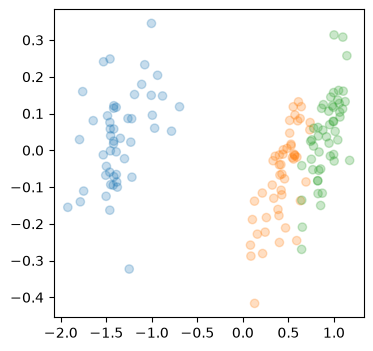

In [2]:
dataset = sklearn.datasets.load_iris()

X,T = numpy.log(0.1+dataset['data']),dataset['target']

Z = sklearn.decomposition.PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(4,4))
plt.scatter(*Z.T,c=T,alpha=0.25,cmap=lcm(['C0','C1','C2']))
plt.show()

We will identify anomalies using the SVDD method presented in the lecture. This method builds an enclosing hypersphere of center $\boldsymbol{c} \in \mathbb{R}^d$ and of squared radius $S$. The dual optimization problem of SVDD, which we derived in the theoretical part of the homework, can be stated in matrix form as:

$$ \max_{\boldsymbol{\alpha}}~~ \boldsymbol{\alpha}^\top D - \boldsymbol{\alpha}^\top XX^\top \boldsymbol{\alpha} $$

where $X$ is a data matrix of size $N \times d$ and where $D = (\|\boldsymbol{x}_1\|^2,\|\boldsymbol{x}_2\|^2,\dots,\|\boldsymbol{x}_N\|^2)$ is the vector containing the squared norm of each data point. This optimization problem is carried out subject to the constraints:

$$ \boldsymbol{1}^\top\boldsymbol{\alpha} = 1 \quad \text{and} \quad \begin{pmatrix}-I\\I\end{pmatrix} \boldsymbol{\alpha} \preceq \begin{pmatrix}\boldsymbol{0}\\C\end{pmatrix} $$

To solve this optimization problem, we can use the quadratic solver from `cvxopt`, specifically the function `cvxopt.solvers.qp`, which is described at the page https://cvxopt.org/userguide/coneprog.html. From the solution of the dual $\boldsymbol{\alpha}$, the parameters of the original problem, i.e. the description of the enclosing hypersphere, can be recovered as: $\boldsymbol{c} = \sum_i \alpha_i \boldsymbol{x}_i$ for the center of the hypersphere, and its squared radius $S$ can be recovered as the squared distance of any data point $\boldsymbol{x}_i$ satisfying $0 < \alpha_i < C$ (note the strict inequalities) from the vector $\boldsymbol{c}$.

**Task:** Implement the function `fit_predict` of the class `SVDD`. It should prepare the matrices and vectors to be fed to `cvxopt`, call `cvxopt` to solve the dual, recover the solution of the primal (the parameters $\boldsymbol{c}$ and $S$) from the solution of the dual, and return a boolean vector of size $N$ indicating which point in the dataset is an outlier.

`cvxopt` wants minimization problems, therefore $$ \max_{\boldsymbol{\alpha}}~~ \boldsymbol{\alpha}^\top D - \boldsymbol{\alpha}^\top XX^\top \boldsymbol{\alpha} \Leftrightarrow \min_{\boldsymbol{\alpha}}~~ \boldsymbol{\alpha}^\top XX^\top \boldsymbol{\alpha} -  \boldsymbol{\alpha}^\top D$$

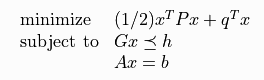

Some intuition to why we choose such matrices. First Lagrangian 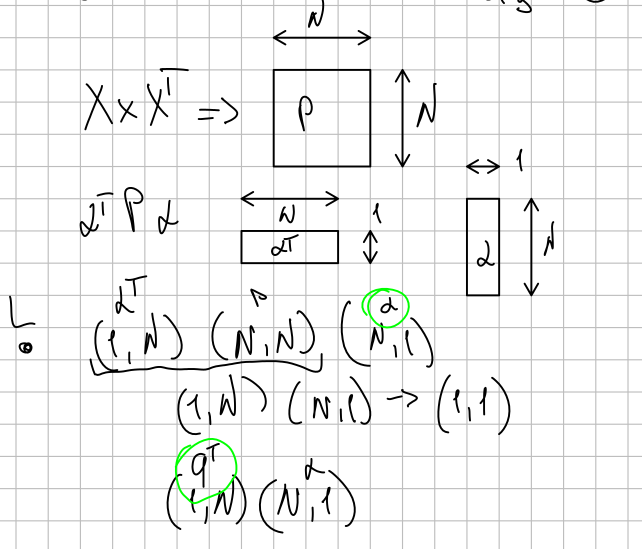

Then equality and inequality constraints 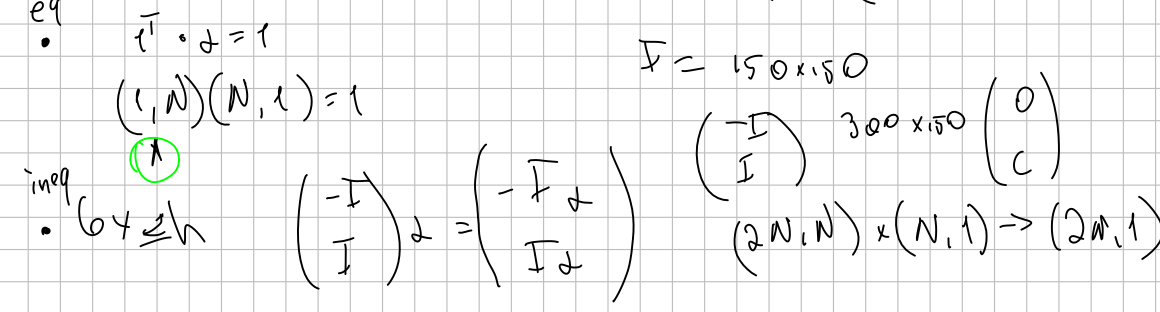

In [3]:
import cvxopt
from cvxopt import solvers

class SVDD:

    def __init__(self,C):
        self.C = C

    def fit_predict(self,X):
        # target (alpha or x) has dims (150, 1)
        n_samples, n_features = X.shape # 150, 4
        I = numpy.identity(n_samples) # 150x150
        # lagrangian itself
        P = 2 * X@X.T # same as np.matmul(X, X.T) 150x150
        # times 2 because 1/2x'*P*x, 1/2 has to be canceled somewhere
        q = -1 * numpy.pow(numpy.linalg.norm(X, axis=1, ord=2), 2).T # (150,) 1 row 150 cols
        #-1 because q=-D
        
        # equality
        A = numpy.ones((1, n_samples)) #must be 1x150
        b = numpy.array([[1.0]]) # 1x1 as Ax is (1,150)x(150,1) = (1,1)
        #inequality
        G = numpy.vstack([-I, I]) # (300, 150)
        h = numpy.expand_dims(numpy.hstack([numpy.zeros(n_samples), self.C*numpy.ones(n_samples)]), axis=1) # (300, 1)
        P_cvx = cvxopt.matrix(P)
        q_cvx = cvxopt.matrix(q)
        G_cvx = cvxopt.matrix(G)
        h_cvx = cvxopt.matrix(h)
        A_cvx = cvxopt.matrix(A)
        b_cvx = cvxopt.matrix(b)

        solution = solvers.qp(P_cvx, q_cvx, G_cvx, h_cvx, A_cvx, b_cvx)
        
        """
            {'x': <150x1 matrix, tc='d'>,
            'y': <1x1 matrix, tc='d'>,
            's': <300x1 matrix, tc='d'>,
            'z': <300x1 matrix, tc='d'>,
            'status': 'optimal',
            'gap': 5.082226061087008e-07,
            'relative gap': 2.572004520224615e-07,
            'primal objective': -1.9759786661040444,
            'dual objective': -1.9759791736263657,
            'primal infeasibility': 1.2320969010076078e-10,
            'dual infeasibility': 4.169066266673848e-16,
            'primal slack': 9.612969532950087e-10,
            'dual slack': 2.0545319420150506e-08,
            'iterations': 9}
        """
        
        alphas = numpy.ravel(solution['x'])
        c = alphas@X
        support_vectors = (alphas > 1e-5) & (alphas < self.C - 1e-5) # if 0 is set, then all are True but most are like 10^-9
        sv_idx = numpy.where(support_vectors)[0][0] # actuallty can be any but we can take first (by def any suffice but we will not check if >1 exist)
        distances = numpy.mean(((c - X) ** 2), axis=1) # from x_i to c
        S = distances[sv_idx] # S = ||c-x_k||^2
        return distances > S
        # ------------------------------------
        # ------------------------------------
        # Build P,q,G,h,A,b for cvxopt.solvers.qp, solve for alpha, recover c and S,
        # return boolean vector (True = outlier)
        # ------------------------------------

The SVDD can now be applied to the Iris dataset. Here, we consider the hyperparameter $C = 0.05$ which allows for a moderate number of outliers. The predictions are rendered in a PCA plot where each instance is color-coded according to its anomaly decision.

     pcost       dcost       gap    pres   dres
 0: -1.9189e+01 -1.5132e+01  1e+03  3e+01  5e-15
 1: -2.7941e+00 -1.4237e+01  5e+01  1e+00  4e-15
 2: -1.6590e+00 -7.0095e+00  6e+00  2e-02  5e-16
 3: -1.7616e+00 -2.8439e+00  1e+00  3e-03  4e-16
 4: -1.8501e+00 -2.2643e+00  4e-01  5e-04  4e-16
 5: -1.9165e+00 -2.0969e+00  2e-01  1e-04  4e-16
 6: -1.9640e+00 -1.9932e+00  3e-02  9e-06  4e-16
 7: -1.9750e+00 -1.9773e+00  2e-03  6e-07  4e-16
 8: -1.9760e+00 -1.9760e+00  5e-05  1e-08  4e-16
 9: -1.9760e+00 -1.9760e+00  5e-07  1e-10  4e-16
Optimal solution found.


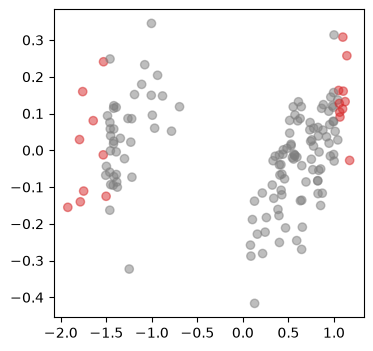

In [4]:
Y = SVDD(0.05).fit_predict(X)

plt.figure(figsize=(4,4))
plt.scatter(*Z.T,c=Y,alpha=0.5,cmap=lcm(['C7','C3']))
plt.show()

As expected, points that are predicted to be anomalous are at the periphery of the data distribution. Yet, the anomaly model appears to be too rigid and fails to account for anomaly scores along the PCA-2 direction. It also fails to account for anomalies between the two clusters. This result can be attributed to the rigidity of the hypersphere model. To address this limitation, we will generate a more detailed, high-dimensional representation of our data, $\Phi(\boldsymbol{x})$, specifically, a 1000-dimensional representation of the data, where each feature $i=1\dots 1000$ of this representation is calculated as

$$ \Phi_i(\boldsymbol{x}) = \cos(\boldsymbol{\omega}_i^\top \boldsymbol{x} + \tau_i) $$

where $\boldsymbol{\omega}$ and $\tau$ are random parameters specified below. This technique is called 'random features'.

**Task:** Implement the mapping onto this feature representation, specifically, a function that takes a matrix of size $N \times 4$, and that produces as an output the desired matrix of size $N \times 1000$.

In [5]:
h = 1000
omega = numpy.random.mtrand.RandomState(0).normal(0,1,[4,h])
tau = numpy.random.mtrand.RandomState(2).uniform(0,2*numpy.pi,[h])

def Phi(X):
    return numpy.cos(X@omega+tau) # i assume we can cheat a little and just do regular matmul as it looks similar to what formula above does
    # ------------------------------------
    # Return the N x 1000 matrix with entries cos(omega_i^T x + tau_i)
    # ------------------------------------
    
# at least it is similar to following slower but more understandable function
# def Phi(X):
#     N = X.shape[0]
#     n_random_features = omega.shape[1]
#     result = numpy.zeros((N, n_random_features))
#     for i in range(N):
#         for j in range(n_random_features):
#             result[i,j] = numpy.cos(omega[:,j].T @ X[i,:] + tau[j])
#     return result

The SVDD can now be retrained on this new data representation. The new anomaly predictions can then be visualized.

     pcost       dcost       gap    pres   dres
 0: -4.5730e+02 -4.0862e+02  2e+03  5e+01  2e-15
 1: -4.0680e+02 -3.7177e+02  5e+02  1e+01  2e-15
 2: -3.6309e+02 -3.3813e+02  2e+02  4e+00  9e-16
 3: -3.4141e+02 -3.2118e+02  1e+02  2e+00  7e-16
 4: -3.1167e+02 -3.0264e+02  9e+01  1e+00  6e-16
 5: -2.9440e+02 -2.8999e+02  4e+01  4e-01  5e-16
 6: -2.8894e+02 -2.8574e+02  3e+01  3e-01  4e-16
 7: -2.8301e+02 -2.8073e+02  2e+01  2e-01  3e-16
 8: -2.7918e+02 -2.7776e+02  1e+01  1e-01  3e-16
 9: -2.7628e+02 -2.7592e+02  8e+00  6e-02  3e-16
10: -2.7453e+02 -2.7465e+02  5e+00  3e-02  3e-16
11: -2.7347e+02 -2.7394e+02  4e+00  2e-02  3e-16
12: -2.7199e+02 -2.7270e+02  7e-01  1e-16  4e-16
13: -2.7230e+02 -2.7236e+02  7e-02  1e-16  4e-16
14: -2.7233e+02 -2.7233e+02  7e-04  2e-16  4e-16
15: -2.7233e+02 -2.7233e+02  7e-06  2e-16  4e-16
Optimal solution found.


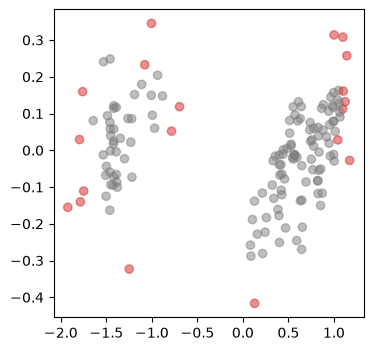

In [6]:
Y = SVDD(0.05).fit_predict(Phi(X))

plt.figure(figsize=(4,4))
plt.scatter(*Z.T,c=Y,alpha=0.5,cmap=lcm(['C7','C3']))
plt.show()

We observe that this nonlinear transformation has made the decision function significantly more flexible, allowing in particular to predict anomalies in a way that better follows the boundaries of the two data clusters.